# 09 · Stage 3: simulated switching points, the minimum amplitude and the second critical rate

**Purpose.** Analyses the simulated staircase runs of notebook 08 with exactly the bench pipeline of notebook 05, then fits the square-root laws, and follows the smallest amplitude reached between bursts as the sweep gets faster. It answers: does the simulation reproduce the bench, and at what rate does the oscillation stop switching off?

**In the report.** Chapter 6: Eqs. (6.1)–(6.3), Figs. 6.2–6.3, Table 6.1, Appendix Table A.2.

## Theory

At bench rates the switching points follow $R_c \pm k\sqrt{\lambda}$ (Eqs. 6.1, 6.2), with $k_{\rm off} = 30.6\,\Omega^{1/2}\mathrm{s}^{1/2}$ predicted.

Per sweep cycle the staircase allows a decay by at most $e^{-\Gamma_-}$, with (notebook 00)

$$\Gamma_- = \frac{\omega_0\,\Delta R\,S_-}{\lambda}, \qquad S_- = \sum_k (G_c - G_k)_+ = 0.329\ \text{(configuration A, } G_c = 3). \tag{2.37}$$

When the growth budget exceeds the decay budget ($\Gamma_+ > \Gamma_-$, true for this path), the oscillation is at full size when the gain turns down, so the smallest amplitude per cycle is, with no free parameter,

$$A_{\min}/A_{\rm sat} = e^{-\Gamma_-}, \tag{2.39}$$

and the oscillation no longer falls below 10 % once $\Gamma_- < \ln 10$, i.e. above $\lambda_c^{(\rm on)} = \omega_0\Delta R\,S_-/\ln 10 = 21.3\ \mathrm{k\Omega/s}$ (Eqs. 2.40, 6.3).

## Method

1. **One run**: the notebook-05 pipeline (trigger, envelope, 90 %/10 % crossings, mid-step resistance) with two simulation settings: the step time is known exactly (`TAU_OVERRIDE_MS` = 312.5/λ in ms), and the envelope window is 0.02 s because the simulated output is sampled every 0.25 ms. At high rates the run is cut into sweep cycles (cycle mode) and warm-up cycles are skipped.
2. **All runs**: read the simulation master table (one row per cycle, all 43 rates).
3. **Fits** below 4.2 kΩ/s, on the true rate: square-root law, fixed delay, free exponent; runs whose 90 % or 10 % point did not fall on the right half of the sweep are left out (`R_sat_valid`, `R_decay_valid`).
4. **Minimum amplitude**: the mean over steady (non-warm-up) cycles of the envelope minimum after each burst, `A_min_after`, against rate; the rate where it crosses 10 % is found by linear interpolation in $\log\lambda$, and compared with $e^{-\Gamma_-}$.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
SIM_FILE   = "../data/stage3/simdata - 1000ohms.csv.gz"   # one simulated run (notebook 08 output)
SIM_RATE   = 1000           # its nominal rate (ohm/s)
SIM_MASTER = "../data/stage3/Masteranalysis_SIM.csv"      # master of all simulated runs (report: 43 rates)
BENCH_MASTER = "../data/stage2/Masteranalysis2.csv"       # bench master, for the comparison table (or None)
MAX_FIT_RATE = 4200.0       # ohm/s, fit range for the square-root laws (report: below 4.2 kOhm/s)
# circuit and analysis settings (configuration A; simulation)
R0, R4, DELTA_R, N_STEPS, STEPS_PER_HALF = 91e3, 47e3, 10e3, 31, 32
LOW, HIGH = 0.10, 0.90
ENV_WINDOW = 0.02           # s (simulations; 0.15 s for bench data)
MIN_BURST_PERIODS, MIN_BURST_PEAK = 10, 0.5
G_C = 3.0                   # threshold of the simulated circuit
OMEGA0 = 1 / (2.17e3 * 1e-6)
OUT_DIR = "outputs/09_stage3"

## 1. The bench pipeline (same functions as notebook 05)

In [2]:
import os, io, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d, minimum_filter1d
from scipy.optimize import curve_fit
os.makedirs(OUT_DIR, exist_ok=True)
STEP_R = DELTA_R / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)
LAMBDA_NOMINAL = SIM_RATE
STEP_DELAY_MS = 312.5 / SIM_RATE * 1000
TAU_OVERRIDE_MS = STEP_DELAY_MS   # exact step time of the simulation

def load_new(path):
    df = pd.read_csv(path)
    if df.shape[1] < 3:
        raise ValueError(f"{path}: expected 3 columns (TIME, CH2 trigger, CH1 Vout), found {df.shape[1]}")
    t_raw = df.iloc[:, 0].to_numpy(float)
    trig = df.iloc[:, 1].to_numpy(float)
    v = df.iloc[:, 2].to_numpy(float)
    n = len(v)
    dt = (t_raw[-1] - t_raw[0]) / (n - 1)
    t = t_raw[0] + dt * np.arange(n)             # rebuild time axis from the sample index
    return t, trig, v, dt


def trigger_fall(t, trig):
    """Falling edge of the CH2 pulse (interpolated) = t0."""
    thr = 0.5 * (np.nanmax(trig) + np.nanmin(trig))
    hi = trig > thr
    falls = np.where(hi[:-1] & ~hi[1:])[0]
    if len(falls) == 0:
        raise ValueError("No falling edge found on CH2 (trigger). Is the pulse inside the file?")
    i = falls[0]
    return t[i] + (thr - trig[i]) * (t[i + 1] - t[i]) / (trig[i + 1] - trig[i])


def dominant_period(v, dt):
    f = np.fft.rfftfreq(len(v), dt)
    A = np.abs(np.fft.rfft(v - v.mean()))
    A[f < 1.0] = 0
    return 1.0 / f[np.argmax(A)]


# ==============================================================================
# Envelope helpers
# ==============================================================================
def runmax(x, n, side):
    """Running max over n samples. side='back': window [i-n+1, i] (unbiased on a rising edge);
    side='fwd': window [i, i+n-1] (unbiased on a falling edge)."""
    o = (n - 1) // 2 if side == "back" else -(n // 2)
    return maximum_filter1d(x, n, origin=o, mode="nearest")


def first_cross_up(t, y, level, lo, hi):
    i = lo + np.argmax(y[lo:hi] >= level)
    if y[i] < level or i == 0:
        return np.nan
    return t[i - 1] + (level - y[i - 1]) * (t[i] - t[i - 1]) / (y[i] - y[i - 1])


def last_cross_down(t, y, level, lo, hi):
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    j = lo + idx[-1]
    if j + 1 >= len(y):
        return np.nan
    return t[j] + (y[j] - level) * (t[j + 1] - t[j]) / (y[j] - y[j + 1])

def tap_of_t(t, t0, tau):
    """Exact tap (staircase) at time t."""
    u = ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)
    up = np.minimum(np.floor(u) + 1, TOP_TAP)
    down = np.maximum(TOP_TAP - 1 - np.floor(u - STEPS_PER_HALF), 0)
    return np.where(u < STEPS_PER_HALF, up, down)


def k_lin_of_t(t, t0, tau):
    """Continuous tap number: straight line through the middle of every step, flat on the holds."""
    u = ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)
    return np.clip(np.minimum(u + 0.5, TOP_TAP + STEPS_PER_HALF - 0.5 - u), 0, TOP_TAP)


def Rlin_of_t(t, t0, tau):
    return R0 + STEP_R * k_lin_of_t(t, t0, tau)


def sweep_position(t, t0, tau):
    """Position inside the sweep in step units: 0 = start of up-ramp, STEPS_PER_HALF = start of down-ramp."""
    return ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)


def branch_of(u):
    """Which part of the triangle a sweep position u lies on (linear model):
    'up'          rising part of the ramp            u <  TOP_TAP - 0.5
    'top hold'    pot parked at the top tap         TOP_TAP - 0.5 <= u < STEPS_PER_HALF - 0.5
    'down'        falling part of the ramp
    'bottom hold' pot parked at tap 0"""
    u = np.asarray(u, float)
    out = np.full(u.shape, "bottom hold", dtype=object)
    out[u < TOP_TAP + STEPS_PER_HALF - 0.5] = "down"
    out[u < STEPS_PER_HALF - 0.5] = "top hold"
    out[u < TOP_TAP - 0.5] = "up"
    out[~np.isfinite(u)] = "n/a"
    return out


def common_period(res):
    """Least-squares sweep period from t90 AND t10 together (same slope, own intercepts)."""
    X, y = [], []
    for k, col in enumerate(["t90", "t10"]):
        for c, val in zip(res["cycle"], res[col]):
            if np.isfinite(val):
                X.append([c, k == 0, k == 1]); y.append(val)
    X, y = np.array(X, float), np.array(y)
    if len(y) == 0 or len(np.unique(X[:, 0])) < 2:
        return np.nan
    return np.linalg.lstsq(X, y, rcond=None)[0][0]

def rail_level(env_sym):
    """Plateau (rail) level of the whole record: median of the envelope within 10 % of its top."""
    top = np.percentile(env_sym, 99.9)
    return float(np.median(env_sym[env_sym >= 0.9 * top]))


def cycle_mode_rows(t, env_sym, t0, T_known, V_rail):
    """CYCLE MODE: one row per sweep cycle, cut at the envelope minima between bursts.
    Cycle k runs from the envelope minimum near the start of sweep cycle k (searched within +/- T/2 of
    t0 + k*T) to the minimum near the start of cycle k+1.
      t90 : first rise of the envelope through HIGH*V_rail after the starting minimum
            (only if that minimum is below HIGH*V_rail, otherwise the oscillation never dropped enough)
      t10 : last fall through LOW*V_rail before the ending minimum - ONLY if that minimum is below
            LOW*V_rail (the oscillation really switched off); otherwise NaN
      A_min_after : envelope at the ending minimum / V_rail   (how far it switched off)
      A_max       : largest envelope in the cycle / V_rail
      warmup      : cycle started before the envelope had reached the rail for the first time"""
    N = len(t)
    above = np.where(env_sym >= HIGH * V_rail)[0]
    i_first_rail = above[0] if len(above) else N
    mins = []
    k = 0
    t_last = t[-1] - ENV_WINDOW                        # the envelope is not reliable at the very end
    while t0 + (k + 0.5) * T_known <= t_last:          # search window must lie fully inside the record
        a = np.searchsorted(t, t0 + (k - 0.5) * T_known)
        b = min(np.searchsorted(t, t0 + (k + 0.5) * T_known), N)
        mins.append(a + int(np.argmin(env_sym[a:b])))
        k += 1
    rows = []
    for k in range(len(mins) - 1):
        lo, hi = mins[k], mins[k + 1]
        t90 = t50u = t10 = t50d = np.nan
        if env_sym[lo] < HIGH * V_rail:
            t90 = first_cross_up(t, env_sym, HIGH * V_rail, lo, hi)
        if env_sym[lo] < 0.5 * V_rail:
            t50u = first_cross_up(t, env_sym, 0.5 * V_rail, lo, hi)
        off = env_sym[hi] < LOW * V_rail
        if np.isfinite(t90) and off:
            i90 = np.searchsorted(t, t90)
            t10 = last_cross_down(t, env_sym, LOW * V_rail, i90, hi + 1)
        if np.isfinite(t50u) and env_sym[hi] < 0.5 * V_rail:
            t50d = last_cross_down(t, env_sym, 0.5 * V_rail, np.searchsorted(t, t50u), hi + 1)
        rows.append(dict(burst=k + 1, cycle=k, vmax=V_rail, A_peak=env_sym[lo:hi + 1].max(),
                         t90=t90, t10=t10, t50_up=t50u, t50_down=t50d,
                         warmup=bool(lo < i_first_rail), switched_off=bool(off),
                         A_min_after=env_sym[hi] / V_rail, A_max=env_sym[lo:hi + 1].max() / V_rail,
                         t_seg_start=t[lo], t_seg_end=t[hi]))
    return rows


def analyse(path):
    t, trig, v, dt = load_new(path)
    N = len(v)
    t0 = trigger_fall(t, trig)
    period = dominant_period(v, dt)
    T_nom = 2 * STEPS_PER_HALF * STEP_DELAY_MS / 1000.0

    # bursts
    w = max(3, int(round(2 * period / dt)))
    amp = 0.5 * (maximum_filter1d(v, w) - minimum_filter1d(v, w))
    ref = np.percentile(amp, 99)
    on = amp > 0.05 * ref
    v = v - np.median(v[~on])                                  # baseline from the quiet parts
    d = np.diff(np.r_[0, on.astype(int), 0])
    s, e = np.where(d == 1)[0], np.where(d == -1)[0]
    keep = (e - s) * dt > MIN_BURST_PERIODS * period
    s, e = s[keep], e[keep]

    # envelope (positive half; running max because the scope may give only ~2 samples / oscillation)
    nW = max(3, int(round(ENV_WINDOW / dt)))
    vpos = np.clip(v, 0, None)
    env_rise, env_dec = runmax(vpos, nW, "back"), runmax(vpos, nW, "fwd")
    env_sym = np.minimum(env_rise, env_dec)       # follows BOTH edges; equals env_rise on rises, env_dec on decays
    V_rail = rail_level(env_sym)
    big = np.array([env_sym[i0:i1].max() >= MIN_BURST_PEAK * V_rail for i0, i1 in zip(s, e)], bool)
    s, e = s[big], e[big]                         # drop small growth bumps (e.g. the first sweep at high rates)
    if len(s) == 0:
        raise ValueError("No oscillation bursts found in CH1.")

    # sanity check of STEP_DELAY_MS against the burst spacing
    T_ref = T_nom
    if len(s) >= 2:
        T_spacing = np.median(np.diff(t[s]))
        if abs(T_spacing / T_nom - 1) > 0.05:
            print(f"WARNING: bursts repeat every {T_spacing:.3f} s but STEP_DELAY_MS = {STEP_DELAY_MS} "
                  f"predicts {T_nom:.3f} s. CHECK STEP_DELAY_MS! Using the burst spacing.")
        T_ref = T_spacing

    pad = int(3 * period / dt)

    # BURST MODE or CYCLE MODE?
    T_known = 2 * STEPS_PER_HALF * TAU_OVERRIDE_MS / 1000.0 if TAU_OVERRIDE_MS is not None else T_nom
    n_expected = int(np.floor((t[-1] - t0) / T_known))       # full sweep cycles inside the record
    mode = "cycle" if len(s) < n_expected else "burst"

    rows = []
    for i0, i1 in (zip(s, e) if mode == "burst" else []):
        lo, hi = max(i0 - pad, 0), min(i1 + pad, N)
        core = slice(i0 + (i1 - i0) // 4, max(i1 - (i1 - i0) // 4, i0 + (i1 - i0) // 4 + 1))
        vmax = np.median(env_rise[core])
        t90 = np.nan if i0 <= pad else first_cross_up(t, env_rise, HIGH * vmax, lo, hi)
        t10 = np.nan if i1 >= N - pad else last_cross_down(t, env_dec, LOW * vmax, lo, hi)
        t50u = np.nan if i0 <= pad else first_cross_up(t, env_rise, 0.5 * vmax, lo, hi)
        t50d = np.nan if i1 >= N - pad else last_cross_down(t, env_dec, 0.5 * vmax, lo, hi)
        cycle = int(np.floor((t[i0] - t0) / T_ref))
        j = min(i1 + int(round(T_known / dt)), N)                  # quiet stretch after this burst
        a_min = env_sym[i1:j].min() / V_rail if j < N else np.nan
        rows.append(dict(burst=len(rows) + 1, cycle=cycle, vmax=vmax, A_peak=env_sym[lo:hi].max(),
                         t90=t90, t10=t10, t50_up=t50u, t50_down=t50d,
                         warmup=False, switched_off=bool(np.isfinite(t10)),
                         A_min_after=a_min, A_max=env_sym[lo:hi].max() / V_rail,
                         t_seg_start=t[i0], t_seg_end=t[min(i1, N - 1)]))
    if mode == "cycle":
        rows = cycle_mode_rows(t, env_sym, t0, T_known, V_rail)
        if not rows:
            raise ValueError("Cycle mode: record shorter than two sweep cycles.")
    res = pd.DataFrame(rows)

    # sweep period and step time
    T = common_period(res)
    if not np.isfinite(T):
        T = T_ref
        print("NOTE: fewer than 2 cycles -> sweep period taken from STEP_DELAY_MS / burst spacing.")
    T_fit = T
    if TAU_OVERRIDE_MS is not None:                      # simulation: the step time is known exactly
        T = 2 * STEPS_PER_HALF * TAU_OVERRIDE_MS / 1000.0
    tau = T / (2 * STEPS_PER_HALF)
    lam = STEP_R / tau

    res["t90_rel"], res["t10_rel"] = res.t90 - t0, res.t10 - t0
    res["tap_sat"], res["tap_decay"] = tap_of_t(res.t90, t0, tau), tap_of_t(res.t10, t0, tau)
    res["R_sat"], res["R_decay"] = Rlin_of_t(res.t90, t0, tau), Rlin_of_t(res.t10, t0, tau)
    res["R_sat_step"] = R0 + STEP_R * res.tap_sat              # resistance actually set at that moment
    res["R_decay_step"] = R0 + STEP_R * res.tap_decay
    res["G_sat"], res["G_decay"] = 1 + res.R_sat / R4, 1 + res.R_decay / R4
    res["R_on50"], res["R_off50"] = Rlin_of_t(res.t50_up, t0, tau), Rlin_of_t(res.t50_down, t0, tau)
    if mode == "burst":
        res["complete_cycle"] = res.t90.notna() & res.t10.notna()
        res["use_decay"] = res.complete_cycle
    else:   # R_sat: every non-warm-up cycle with a t90; R_decay: only cycles that really switched off
        res["complete_cycle"] = res.t90.notna() & ~res.warmup
        res["use_decay"] = res.complete_cycle & res.t10.notna()
    res["u90"], res["u10"] = sweep_position(res.t90, t0, tau), sweep_position(res.t10, t0, tau)
    res["t90_branch"], res["t10_branch"] = branch_of(res.u90), branch_of(res.u10)
    res["sat_on_upramp"] = res.t90_branch == "up"           # R_sat is a real onset threshold only then
    res["decay_on_downramp"] = res.t10_branch == "down"     # R_decay is a real offset threshold only then

    info = dict(t0=t0, T=T, T_fit=T_fit, T_nom=T_nom, tau=tau, lam=lam, period=period, dt=dt, n_samples=N,
                t_start=t[0], t_end=t[-1], mode=mode, V_rail=V_rail, n_bursts_found=len(s),
                n_cycles_expected=n_expected)
    return res, info, (t, trig, v, env_sym)

## 2. Analyse the sample run and compare with the master

In [3]:
res, info, arrays = analyse(SIM_FILE)
full, dec = res[res.complete_cycle], res[res.use_decay]
print(f"{info['mode']} mode, true rate {info['lam']:.1f} ohm/s; R_on = {full.R_sat.mean():.1f} ohm, R_off = {dec.R_decay.mean():.1f} ohm")
ref = pd.read_csv(SIM_MASTER).groupby("lambda_nominal").first().loc[SIM_RATE]
ok = abs(full.R_sat.mean() - ref.R_sat_mean) < 0.5 and abs(dec.R_decay.mean() - ref.R_decay_mean) < 0.5
print(("PASS" if ok else "FAIL") + f" same as the report's master: R_on {ref.R_sat_mean:.1f}, R_off {ref.R_decay_mean:.1f}")

burst mode, true rate 1032.3 ohm/s; R_on = 95617.8 ohm, R_off = 93027.6 ohm
PASS same as the report's master: R_on 95617.8, R_off 93027.6


## 3. Square-root fits over all simulated runs (Eqs. 6.1, 6.2)

In [4]:
def as_bool(s): return s.astype(str).str.lower().isin(["true", "1", "1.0"])
m = pd.read_csv(SIM_MASTER); g = m.groupby("lambda_nominal").first().reset_index().sort_values("lambda_measured")
lam = g.lambda_measured.to_numpy(float)
on = g[(lam <= MAX_FIT_RATE) & as_bool(g.R_sat_valid)]; off = g[(lam <= MAX_FIT_RATE) & as_bool(g.R_decay_valid)]
def aic(r, p): return len(r) * np.log((r**2).sum() / len(r)) + 2 * p
fit = {}
for name, d, col, sg in (("switch-on", on, "R_sat_mean", 1), ("switch-off", off, "R_decay_mean", -1)):
    x, y = d.lambda_measured.to_numpy(float), d[col].to_numpy(float)
    p, c = curve_fit(lambda l, R, k: R + sg * k * np.sqrt(l), x, y, p0=[94000, 40])
    p3, c3 = curve_fit(lambda l, R, k, a: R + sg * k * l**a, x, y, p0=[94000, 40, 0.5], maxfev=20000)
    fit[name] = dict(R=p[0], R_err=np.sqrt(c[0, 0]), k=p[1], k_err=np.sqrt(c[1, 1]), a=p3[2], a_err=np.sqrt(c3[2, 2]), n=len(x))
    f = fit[name]
    print(f"{name} ({f['n']} rates): R = {f['R']:.0f} +/- {f['R_err']:.0f} ohm, k = {f['k']:.2f} +/- {f['k_err']:.2f}, free exponent {f['a']:.3f} +/- {f['a_err']:.3f}")
k_th = 2 * np.sqrt(np.log(10) * R4 / OMEGA0)
L_on = fit["switch-on"]["k"]**2 * OMEGA0 / (4 * R4)
print(f"k_off theory {k_th:.2f} ({100*(fit['switch-off']['k']/k_th-1):+.1f} %), Lambda_on = {L_on:.2f}")

switch-on (23 rates): R = 93934 +/- 18 ohm, k = 52.39 +/- 0.42, free exponent 0.510 +/- 0.022
switch-off (23 rates): R = 94006 +/- 4 ohm, k = 30.30 +/- 0.08, free exponent 0.485 +/- 0.007
k_off theory 30.65 (-1.1 %), Lambda_on = 6.73


## 4. Bench and simulation compared (Table 6.1)

In [5]:
if BENCH_MASTER:
    gb = pd.read_csv(BENCH_MASTER).groupby("lambda_nominal").first().reset_index()
    lb = gb.lambda_measured.to_numpy(float); vb = as_bool(gb.R_sat_valid).to_numpy()
    fb = {}
    for name, sel, col, sg in (("on", vb & (lb < 3500), "R_sat_mean", 1), ("off", lb < 4500, "R_decay_mean", -1)):
        p, c = curve_fit(lambda l, R, k: R + sg * k * np.sqrt(l), lb[sel], gb[col].to_numpy(float)[sel], p0=[97000, 40]); fb[name] = (p, np.sqrt(np.diag(c)))
    tab = pd.DataFrame({
        "bench (Stage 2)": [fb["off"][0][0], 1 + fb["off"][0][0] / R4, fb["off"][0][1], fb["on"][0][1], fb["on"][0][1] / fb["off"][0][1]],
        "simulation (Stage 3)": [fit["switch-off"]["R"], 1 + fit["switch-off"]["R"] / R4, fit["switch-off"]["k"], fit["switch-on"]["k"], fit["switch-on"]["k"] / fit["switch-off"]["k"]],
        "theory": [2 * R4, 3.0, k_th, np.nan, np.nan]},
        index=["threshold R_c (switch-off fit), ohm", "threshold gain G_c", "k_off", "k_on", "k_on / k_off"])
    print(tab.round(3).to_string()); tab.to_csv(os.path.join(OUT_DIR, "table_6_1.csv"))

                                     bench (Stage 2)  simulation (Stage 3)     theory
threshold R_c (switch-off fit), ohm        97472.317             94006.094  94000.000
threshold gain G_c                             3.074                 3.000      3.000
k_off                                         31.827                30.297     30.649
k_on                                          58.136                52.390        NaN
k_on / k_off                                   1.827                 1.729        NaN


## 5. Minimum amplitude between bursts and the second critical rate (Fig. 6.3, Eq. 6.3)

10 % crossing between 20.6 and 25.8 kOhm/s, interpolated 21.1 kOhm/s; predicted 21.3 kOhm/s
above 15 kOhm/s: largest relative deviation from exp(-Gamma_-) = 2.2 %


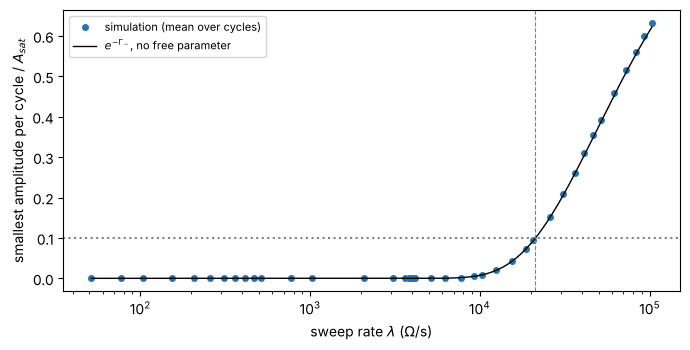

In [6]:
m["warmup"] = as_bool(m.warmup)
st = m[~m.warmup & m.A_min_after.notna()].groupby("lambda_nominal").agg(lam=("lambda_measured", "first"), A_min=("A_min_after", "mean")).reset_index().sort_values("lam")
x, y = st.lam.to_numpy(float), st.A_min.to_numpy(float)
lam_cross, bracket = np.nan, None
for i in range(len(x) - 1):
    if y[i] < LOW <= y[i + 1]:
        f = (LOW - y[i]) / (y[i + 1] - y[i]); lam_cross = np.exp(np.log(x[i]) + f * (np.log(x[i + 1]) - np.log(x[i]))); bracket = (x[i], x[i + 1]); break
taps = np.arange(32); Gk = 1 + (R0 + STEP_R * taps) / R4
S_minus = np.clip(G_C - Gk, 0, None).sum()
lam_c_on = OMEGA0 * STEP_R * S_minus / np.log(10)
print(f"10 % crossing between {bracket[0]/1e3:.1f} and {bracket[1]/1e3:.1f} kOhm/s, interpolated {lam_cross/1e3:.1f} kOhm/s; predicted {lam_c_on/1e3:.1f} kOhm/s")
hi = st.lam > 15000
pred = np.exp(-OMEGA0 * STEP_R * S_minus / st.lam)
print(f"above 15 kOhm/s: largest relative deviation from exp(-Gamma_-) = {np.max(np.abs(st.A_min[hi] / pred[hi] - 1))*100:.1f} %")
L = np.logspace(np.log10(x.min()), np.log10(x.max()), 300)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(x, y, "o", ms=4, label="simulation (mean over cycles)")
ax.semilogx(L, np.exp(-OMEGA0 * STEP_R * S_minus / L), "k", lw=1, label=r"$e^{-\Gamma_-}$, no free parameter")
ax.axhline(LOW, color="gray", ls=":"); ax.axvline(lam_c_on, color="gray", ls="--", lw=0.8)
ax.set_xlabel(r"sweep rate $\lambda$ ($\Omega$/s)"); ax.set_ylabel(r"smallest amplitude per cycle / $A_{sat}$"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "min_amplitude.png"), dpi=150); plt.show()

## Check against the report

In [7]:
so, sf = fit["switch-on"], fit["switch-off"]
checks = {
    "Eq. 6.1: R_on = (93934 +/- 18) + (52.4 +/- 0.4) sqrt(lambda), 23 rates": abs(so["R"] - 93934) < 1 and abs(so["k"] - 52.4) < 0.05 and so["n"] == 23,
    "Eq. 6.2: R_off = (94006 +/- 4) - (30.30 +/- 0.08) sqrt(lambda)": abs(sf["R"] - 94006) < 1 and abs(sf["k"] - 30.30) < 0.005,
    "free exponents 0.485 +/- 0.007 (off), 0.51 +/- 0.02 (on)": abs(sf["a"] - 0.485) < 0.001 and abs(so["a"] - 0.51) < 0.005,
    "Lambda_on = 6.7": abs(L_on - 6.7) < 0.05,
    "10 % crossing between 20.6 and 25.8 kOhm/s, about 21.1 by interpolation": abs(bracket[0] - 20600) < 100 and abs(bracket[1] - 25800) < 100 and abs(lam_cross - 21100) < 100,
    "Eq. 6.3: predicted 21.3 kOhm/s": abs(lam_c_on - 21300) < 50,
}
for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)

PASS Eq. 6.1: R_on = (93934 +/- 18) + (52.4 +/- 0.4) sqrt(lambda), 23 rates
PASS Eq. 6.2: R_off = (94006 +/- 4) - (30.30 +/- 0.08) sqrt(lambda)
PASS free exponents 0.485 +/- 0.007 (off), 0.51 +/- 0.02 (on)
PASS Lambda_on = 6.7
PASS 10 % crossing between 20.6 and 25.8 kOhm/s, about 21.1 by interpolation
PASS Eq. 6.3: predicted 21.3 kOhm/s


## Using your own data

Simulate with notebook 08 (or provide files in the same format), analyse each run with section 1–2 (or notebook 05 with `TAU_OVERRIDE_MS` and `ENV_WINDOW = 0.02`), and point `SIM_MASTER` at the resulting master. For another staircase, change `R0`, `R4`, `DELTA_R` and `G_C`; $S_-$ is recomputed from them.